In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageFile
import os
import math
from pathlib import Path


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    TensorDataset,
    random_split
)
import torchvision.transforms as transforms
from torchsummary import summary
from transformers import AutoImageProcessor, AutoModel
from collections import defaultdict
from sklearn.metrics import roc_curve, auc
from tqdm.auto import tqdm
import warnings
import random


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


ImageFile.LOAD_TRUNCATED_IMAGES = True

In [3]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
torch.cuda.manual_seed_all(42)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("evanwang98/fingerveinsyn-5m-part")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/evanwang98/fingerveinsyn-5m-part


In [4]:
class FingerVeinDataset(Dataset):

    def __init__(
        self,
        root_dir,
        class_ids=None,
        transform=None
    ):

        self.root_dir = Path(root_dir)
        self.transform = transform
        self.samples = []

        self.clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        all_folders = [
            f for f in self.root_dir.iterdir()
            if f.is_dir()
        ]

        all_folders.sort(
            key=lambda x: x.name
        )

        # If no class_ids are provided, use all classes
        if class_ids is None:
            class_ids = list(range(len(all_folders)))

        # Keep original class IDs if needed later
        self.class_ids = class_ids

        selected_folders = [
            all_folders[i]
            for i in class_ids
        ]

        # Labels are remapped to 0...len(class_ids)-1
        for label, folder_path in enumerate(selected_folders):

            image_paths = sorted(
                folder_path.glob("*.png")
            )

            for img_path in image_paths:

                self.samples.append(
                    (str(img_path), label)
                )

        print(
            f"Loaded {len(selected_folders)} classes with "
            f"a total of {len(self.samples)} images."
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        img_path, label = self.samples[idx]

        img_pil = Image.open(img_path).convert("L")
        img_np = np.array(img_pil)

        clahe_img = self.clahe.apply(img_np)

        stacked_np = np.stack(
            [clahe_img, clahe_img, clahe_img],
            axis=-1
        )

        image = Image.fromarray(stacked_np)

        if self.transform:
            image = self.transform(image)

        return image, label
            

In [5]:
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.2370, 0.2370, 0.2370], 
        std=[0.1592, 0.1592, 0.1592]
    )
])

dataset_path = "/kaggle/input/datasets/evanwang98/fingerveinsyn-5m-part/FingerVeinSyn5M(4001-5000)"

master_dataset = FingerVeinDataset(
    root_dir=dataset_path,
    class_ids=list(range(200)),
    transform=data_transforms
)

train_indices = []
val_indices = []
test_indices = []

for idx in range(len(master_dataset)):

    img_pos = idx % 100   

    if img_pos < 15:
        test_indices.append(idx)

    elif img_pos < 30:
        val_indices.append(idx)

    else:
        train_indices.append(idx)

train_dataset = Subset(master_dataset, train_indices)
val_dataset   = Subset(master_dataset, val_indices)
test_dataset  = Subset(master_dataset, test_indices)
        
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

unknown_dataset = FingerVeinDataset(
    root_dir=dataset_path,
    class_ids=list(range(200, 250)),
    transform=data_transforms
)
        
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")
print(f"Test unknown dataset size: {len(unknown_dataset)}")

Loaded 200 classes with a total of 20000 images.
Train dataset size: 14000
Validation dataset size: 3000
Test dataset size: 3000
Loaded 50 classes with a total of 5000 images.
Train dataset size: 14000
Validation dataset size: 3000
Test dataset size: 3000
Test unknown dataset size: 5000


In [6]:
batch_size = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True,      
    num_workers=4,     
    pin_memory=True    
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    shuffle=False,     
    num_workers=4,     
    pin_memory=True    
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4
)

unknown_test_loader = DataLoader(
    unknown_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4
)

images, labels = next(iter(train_loader))
print(f"Batch ecg images shape: {images.shape}") 
print(f"Batch labels shape: {labels.shape}") 
print(f"Min label: {labels.min().item()}, Max label: {labels.max().item()}") 

Batch ecg images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])
Min label: 0, Max label: 195


In [ ]:
class VeinCNN(nn.Module):
    def __init__(self, in_channels=3, emb_dim=512):
        super(VeinCNN, self).__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(64)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(128, 128, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(128)
        )
                
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(256, 256, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(256)
        )
 
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(7 * 7 * 512, 1024),
        nn.BatchNorm1d(1024),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(1024, emb_dim)
        )

    def forward(self, x):
     
        x = self.block1(x)
        
        x = self.block2(x)
        
        x = self.block3(x)

        x = self.block4(x)

        x = self.block5(x)
        x = self.fc(x)
        return x

In [8]:
class ArcFaceLoss(nn.Module):
    def __init__(self, in_features, num_classes, s=64.0, m=0.5, easy_margin=False):
        super().__init__()

        self.in_features = in_features
        self.num_classes = num_classes

        self.s = s
        self.m = m
        self.easy_margin = easy_margin

        self.weight = nn.Parameter(torch.empty(num_classes, in_features))
        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m)
        self.mm = math.sin(math.pi - m) * m


    def forward(self, embeddings, labels):
       
        embeddings = F.normalize(embeddings, dim=1)
        weight = F.normalize(self.weight, dim=1)

        cosine = F.linear(embeddings, weight)  

        cosine = cosine.clamp(-1.0 + 1e-7, 1.0 - 1e-7)

        sine = torch.sqrt(1.0 - cosine.pow(2))
        phi = cosine * self.cos_m - sine * self.sin_m

        if self.easy_margin:
            phi = torch.where(cosine > 0, phi, cosine)
        else:
            phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = torch.zeros_like(cosine)
        one_hot.scatter_(1, labels.view(-1, 1), 1.0)

        logits = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        logits *= self.s

        loss = F.cross_entropy(logits, labels)

        return loss, cosine

In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

lr = 1e-4
weight_decay = 1e-4
num_classes = 200

model = VeinCNN(emb_dim=512).to(device)
print(model)
print(summary(model,(3,224,224)))

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

outputs = model(images)
print(f"Output shape: {outputs.shape}")

criterion = ArcFaceLoss(
    in_features=512,
    num_classes=num_classes,
    s=64,
    m=0.5
).to(device)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(criterion.parameters()),
    lr=1e-4, weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)


cuda
VeinCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), paddi

In [10]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_acc = 0.0
        self.counter = 0
        self.stop = False

    def __call__(self, val_acc):
        if val_acc > self.best_acc + self.min_delta:
            self.best_acc = val_acc
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

In [11]:
scaler = torch.amp.GradScaler("cuda")

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            embeddings = model(images)
            loss, _ = criterion(embeddings, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [12]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    correct = 0
    total = 0
    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        embeddings = model(images)

        loss, cosine = criterion(embeddings, labels)
        running_loss += loss.item()

        weight = F.normalize(criterion.weight, dim=1)
        logits = embeddings @ weight.T

        preds = logits.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / len(loader), 100.0 * correct / total

In [13]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 30
early_stopping = EarlyStopping(patience=5, min_delta=1e-4)
best_val_acc = 0.0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_acc)
    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/30] Train Loss: 34.4477 | Val Loss: 25.8574 | Val Accuracy: 82.03% 
--> Best model saved.
Epoch [2/30] Train Loss: 19.6434 | Val Loss: 7.6265 | Val Accuracy: 96.40% 
--> Best model saved.
Epoch [3/30] Train Loss: 6.3390 | Val Loss: 2.9386 | Val Accuracy: 98.87% 
--> Best model saved.
Epoch [4/30] Train Loss: 2.0429 | Val Loss: 1.6096 | Val Accuracy: 99.70% 
--> Best model saved.
Epoch [5/30] Train Loss: 0.8449 | Val Loss: 1.3342 | Val Accuracy: 99.77% 
--> Best model saved.
Epoch [6/30] Train Loss: 0.4191 | Val Loss: 0.9259 | Val Accuracy: 99.93% 
--> Best model saved.
Epoch [7/30] Train Loss: 0.2355 | Val Loss: 0.9745 | Val Accuracy: 99.80% 
Epoch [8/30] Train Loss: 0.1481 | Val Loss: 1.0039 | Val Accuracy: 99.83% 
Epoch [9/30] Train Loss: 0.1181 | Val Loss: 0.8740 | Val Accuracy: 99.87% 
Epoch [10/30] Train Loss: 0.1106 | Val Loss: 0.8517 | Val Accuracy: 99.87% 
Epoch [11/30] Train Loss: 0.0920 | Val Loss: 0.8261 | Val Accuracy: 99.87% 
--> Early stopping triggered.


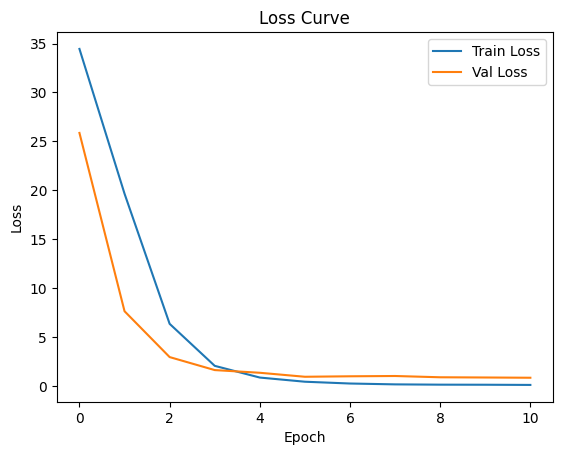

In [14]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

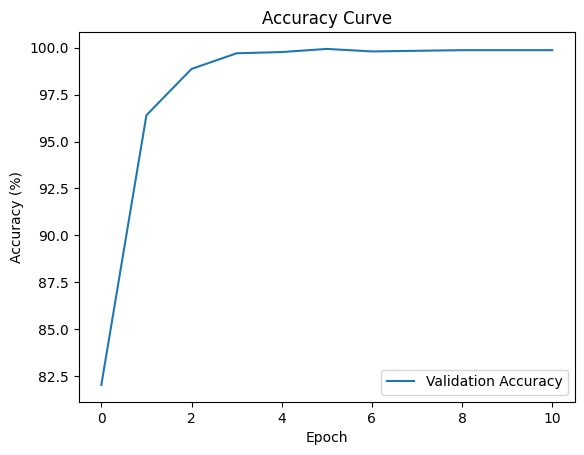

In [15]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    weight = F.normalize(
        criterion.weight,
        dim=1
    )

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        embs = F.normalize(
            model(images),
            dim=1
        )

        logits = embs @ weight.T

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [17]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 100.00%
Rank-5 Accuracy : 100.00%
Rank-10 Accuracy: 100.00%
Precision       : 100.00%
Recall          : 100.00%
F1 Score        : 100.00%


In [18]:
torch.save(model.state_dict(), "Vein-Model-Weight")

In [19]:
model_1 = VeinCNN(emb_dim=512)

model_1.load_state_dict(
    torch.load("/kaggle/working/Vein-Model-Weight")
)

model_1.to(device)

VeinCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2

In [20]:
model_2 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_2 = model_2.to(device)
model_2.eval()

print(model_2)
print(summary(model_2, (3, 224, 224)))

dummy_image = torch.randn(1, 3, 224, 224).to(device) 
with torch.no_grad():

    features = model_2(dummy_image)

print("Extracted feature shape:", features.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_pretrain.pth


100%|██████████| 1.13G/1.13G [00:03<00:00, 311MB/s]


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-23): 24 x NestedTensorBlock(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, element

In [22]:
@torch.no_grad()
def extract_fused_features(loader, model_1, model_2, device):

    model_1.eval()
    model_2.eval()

    features = []
    labels = []

    for images, target in loader:

        images = images.to(device, non_blocking=True)

        f1 = model_1(images)
        f2 = model_2(images)

        f1 = F.normalize(f1, dim=1)
        f2 = F.normalize(f2, dim=1)

        fused = torch.cat([f1, f2], dim=1)

        features.append(fused.cpu())
        labels.append(target)

    features = torch.cat(features, dim=0)
    labels = torch.cat(labels, dim=0)

    return features.numpy(), labels.numpy()

In [23]:
warnings.filterwarnings("ignore")

X_train, y_train = extract_fused_features(
    train_loader,
    model_1,
    model_2,
    device
)

X_val, y_val = extract_fused_features(
    val_loader,
    model_1,
    model_2,
    device
)

X_test, y_test = extract_fused_features(
    test_loader,
    model_1,
    model_2,
    device
)

X_test_unknown, y_test_unknown = extract_fused_features(
   unknown_test_loader,
    model_1,
    model_2,
    device
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Test(unknown) :", X_test_unknown.shape, y_test_unknown.shape)

Train: (14000, 1536) (14000,)
Val  : (3000, 1536) (3000,)
Test : (3000, 1536) (3000,)
Test(unknown) : (5000, 1536) (5000,)


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train_ml = normalize(X_train)
X_val_ml = normalize(X_val)
X_test_ml = normalize(X_test)

pipeline = make_pipeline(

    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),

    StandardScaler(),

    SVC(
        kernel='rbf',
        probability=True
    )
)

pipeline.fit(X_train_ml, y_train)

val_pred = pipeline.predict(X_val_ml)

val_acc = accuracy_score(
    y_val,
    val_pred
)

print("Validation Accuracy:", val_acc)

y_pred = pipeline.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 0.9986666666666667
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [25]:
from sklearn.svm import LinearSVC

model = make_pipeline(
    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=10000
    )
)

model.fit(X_train_ml, y_train)

val_pred = model.predict(X_val_ml)
val_acc = accuracy_score(y_val, val_pred)

print("Validation Accuracy:", val_acc)

y_pred = model.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 0.9993333333333333
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [26]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine'
)

knn.fit(X_train_ml, y_train)

y_pred = knn.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [27]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=5000,
    class_weight='balanced'
)

lr.fit(X_train_ml, y_train)

y_pred = lr.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [28]:
X_train_tensor = torch.from_numpy(X_train).float()
y_train_tensor = torch.from_numpy(y_train).long()

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

X_val_tensor = torch.from_numpy(X_val).float()
y_val_tensor = torch.from_numpy(y_val).long()

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

X_test_tensor = torch.from_numpy(X_test).float()
y_test_tensor = torch.from_numpy(y_test).long()

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

X_test_unknown_tensor = torch.from_numpy(X_test_unknown).float()
y_test_unknown_tensor = torch.from_numpy(y_test_unknown).long()

unknown_test_dataset = TensorDataset(
    X_test_unknown_tensor,
    y_test_unknown_tensor
)

In [30]:
# ------------------- Train -------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ------------------- Validation -------------------
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------- Test -------------------
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------- Unknown Test -------------------
unknown_test_loader = DataLoader(
    unknown_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [33]:
class FusionClassifier(nn.Module):

    def __init__(self,
                 input_dim=2048,
                 num_classes=200):

        super().__init__()

        self.features = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True)
        )

        self.classifier = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):

        feat = self.features(x)

        logits = self.classifier(feat)

        return logits, feat

In [34]:
lr = 1e-4
weight_decay = 1e-4

model = FusionClassifier(input_dim=1536, num_classes=200).to(device)

print(model)
print(summary(model, (1536,)))


images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

logits, feat = model(images)

print("Logits shape:", logits.shape)
print("Feature shape:", feat.shape)

criterion = nn.CrossEntropyLoss().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3
)

FusionClassifier(
  (features): Sequential(
    (0): Linear(in_features=1536, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
  )
  (classifier): Linear(in_features=512, out_features=200, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 1024]       1,573,888
       BatchNorm1d-2                 [-1, 1024]           2,048
              ReLU-3                 [-1, 1024]               0
           Dropout-4                 [-1, 1024]               0
            Linear-5                  [-1, 512]         524,800
       BatchNorm1d-6         

In [36]:
scaler = torch.amp.GradScaler("cuda")
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits, feat = model(features)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [37]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits, _ = model(features)
        loss = criterion(logits, labels)

        running_loss += loss.item()

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy

In [38]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 100
early_stopping = EarlyStopping(patience=25, min_delta=1e-4)
best_val_acc = 0.0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_acc)
    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/100] Train Loss: 1.6142 | Val Loss: 0.3899 | Val Accuracy: 99.80% 
--> Best model saved.
Epoch [2/100] Train Loss: 0.1380 | Val Loss: 0.1644 | Val Accuracy: 99.90% 
--> Best model saved.
Epoch [3/100] Train Loss: 0.0469 | Val Loss: 0.1146 | Val Accuracy: 99.83% 
Epoch [4/100] Train Loss: 0.0244 | Val Loss: 0.0893 | Val Accuracy: 99.90% 
Epoch [5/100] Train Loss: 0.0142 | Val Loss: 0.0765 | Val Accuracy: 99.87% 
Epoch [6/100] Train Loss: 0.0102 | Val Loss: 0.0700 | Val Accuracy: 99.87% 
Epoch [7/100] Train Loss: 0.0082 | Val Loss: 0.0643 | Val Accuracy: 99.87% 
Epoch [8/100] Train Loss: 0.0066 | Val Loss: 0.0611 | Val Accuracy: 99.87% 
Epoch [9/100] Train Loss: 0.0052 | Val Loss: 0.0566 | Val Accuracy: 99.87% 
Epoch [10/100] Train Loss: 0.0043 | Val Loss: 0.0547 | Val Accuracy: 99.87% 
Epoch [11/100] Train Loss: 0.0039 | Val Loss: 0.0523 | Val Accuracy: 99.87% 
Epoch [12/100] Train Loss: 0.0034 | Val Loss: 0.0499 | Val Accuracy: 99.87% 
Epoch [13/100] Train Loss: 0.0029 | Val L

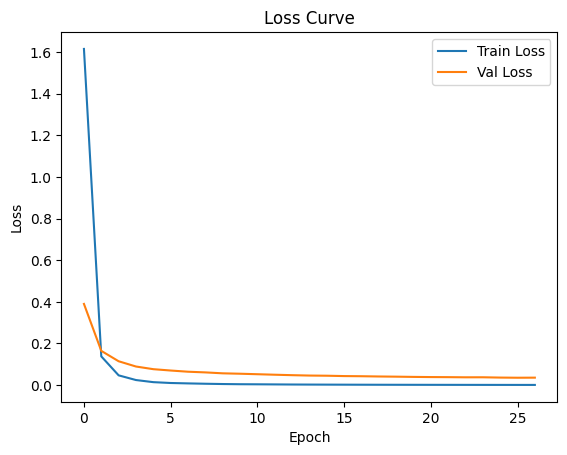

In [39]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

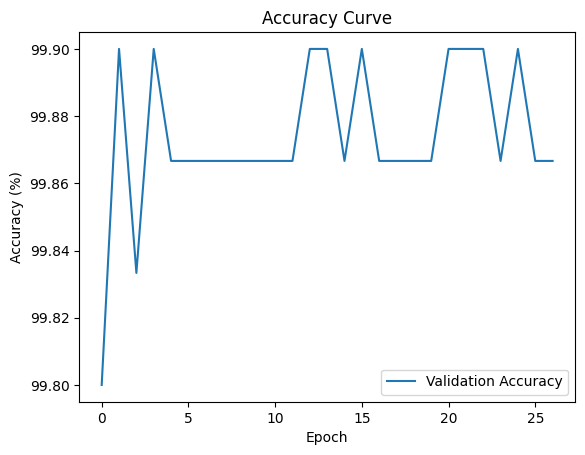

In [40]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [41]:
model.load_state_dict(
    torch.load("best_model.pth")
)

<All keys matched successfully>

In [42]:
@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _ = model(features)

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [43]:
@torch.no_grad()
def compute_cmc(
    model,
    loader,
    device,
    max_rank=20
):

    model.eval()

    cmc = np.zeros(max_rank)
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _ = model(features)

        ranks = logits.argsort(
            dim=1,
            descending=True
        )

        for i in range(labels.size(0)):

            pos = (
                ranks[i] == labels[i]
            ).nonzero(
                as_tuple=True
            )[0].item()

            if pos < max_rank:
                cmc[pos:] += 1

        total += labels.size(0)

    return cmc / total

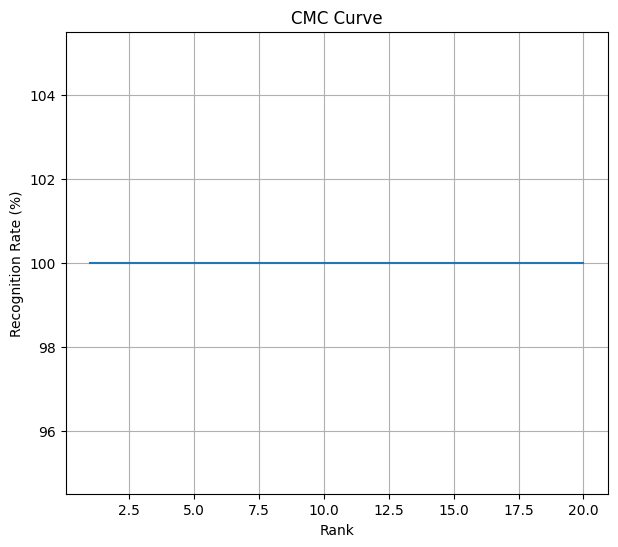

In [44]:
cmc = compute_cmc(
    model,
    test_loader,
    device
)

plt.figure(figsize=(7,6))

plt.plot(
    np.arange(1, len(cmc)+1),
    cmc * 100
)

plt.xlabel("Rank")
plt.ylabel("Recognition Rate (%)")
plt.title("CMC Curve")

plt.grid(True)
plt.show()

In [45]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 100.00%
Rank-5 Accuracy : 100.00%
Rank-10 Accuracy: 100.00%
Precision       : 100.00%
Recall          : 100.00%
F1 Score        : 100.00%
